# Risco territorial de violência letal contra a mulher — Pipeline de Data Science

**Projeto Integrador — 2º semestre de 2026 · Entrega 4 · Tema: Violência contra a Mulher (Aplicativo de Apoio Camuflado)**

> **Aviso (protótipo acadêmico):** o resultado deste notebook é uma **estimativa acadêmica** do *contexto territorial*
> (município) de violência letal contra mulheres. **Não** estima o risco de nenhuma pessoa, **não** substitui os serviços
> oficiais de proteção e **não** deve ser usado para decisões reais. Em risco imediato, ligue **190** ou **180**.

**Pergunta de negócio.** Dado o histórico recente de um município, qual a probabilidade de ele estar, no ano seguinte, entre os
25% com maior taxa de homicídios de mulheres? O app mostra essa estimativa (Baixo / Médio / Alto) no Espaço Seguro,
sempre com o aviso acima.

**Pipeline:** governança → qualidade → tratamento → análise exploratória → modelagem (2 modelos + linha de base, validação cruzada)
→ avaliação → integração com a API/app.

**Autoria das etapas** (divisão do grupo — Seção 3.3 do Documento Orientador):

| Etapa | Responsável |
|---|---|
| 1–2. Base, governança e dicionário | Nicolas Toshio |
| 3–4. Qualidade e tratamento | Nicolas Toshio |
| 5. Análise exploratória | Fernando Vinicius |
| 6–7. Modelagem e avaliação | Fernando Vinicius |
| 8. Integração com o app | Nicolas Toshio |

Para reproduzir: `pip install -r requirements.txt` → (opcional) `python baixar_dados.py` → *Restart & Run All*.

In [1]:
import json, pathlib, warnings, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
DADOS = pathlib.Path("dados")
ALEATORIO = 42                       # semente fixa: o notebook sempre reproduz os mesmos números
POP_MINIMA = 20_000                  # cobertura do modelo (ver Seção 6)
ANOS_TREINO = range(2013, 2021)      # anos-alvo usados para treinar
ANOS_TESTE = [2021, 2022]            # anos-alvo reservados para o teste (validação temporal)

pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = None
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold"})
COR, COR2, COR3 = "#B3261E", "#1F3A5F", "#7A7A7A"

UF_SIGLA = {"11": "RO", "12": "AC", "13": "AM", "14": "RR", "15": "PA", "16": "AP", "17": "TO", "21": "MA", "22": "PI",
            "23": "CE", "24": "RN", "25": "PB", "26": "PE", "27": "AL", "28": "SE", "29": "BA", "31": "MG", "32": "ES",
            "33": "RJ", "35": "SP", "41": "PR", "42": "SC", "43": "RS", "50": "MS", "51": "MT", "52": "GO", "53": "DF"}
REGIAO = {"1": "Norte", "2": "Nordeste", "3": "Sudeste", "4": "Sul", "5": "Centro-Oeste"}
print("Ambiente pronto.")

Ambiente pronto.


## 1. Escolha e justificativa da base  _(Responsável: Nicolas Toshio)_

| Item | Informação |
|---|---|
| **Base** | **Atlas da Violência** (Ipea e Fórum Brasileiro de Segurança Pública), séries municipais de homicídios e população |
| **Fonte** | Ipeadata — API OData pública: `http://www.ipeadata.gov.br/api/odata4` (séries `AVIOL12_HOMICF`, `AVIOL12_HOMICM`, `AVIOL12_HOMIC`, `AVIOL12_VIOLPOP`) |
| **Órgão responsável** | Ipea (organização e publicação); dados primários do Sistema de Informações sobre Mortalidade (SIM/DataSUS, Ministério da Saúde); população: estimativas TCU/IBGE |
| **Está entre as bases sugeridas?** | Sim — o Atlas da Violência é uma das bases listadas na Seção 5.3 do Documento Orientador, portanto não precisa de aprovação extra |

**Por que serve ao tema e ao app.** O app apoia mulheres em situação de violência. O Atlas traz **homicídios de mulheres por município e por ano**
(o desfecho mais grave da violência de gênero e o mais bem registrado). Com ele é possível estimar o **contexto territorial** de cada município
e mostrá-lo de forma simples no Espaço Seguro. A base é pública, agregada (sem identificação de pessoas) e cobre os 5.570 municípios.

**O que a base NÃO mede.** Ela registra apenas mortes. Não mede violência não letal (psicológica, patrimonial, moral, sexual sem morte),
que é a maioria dos casos e é fortemente **subnotificada**. Por isso o indicador é do *território*, nunca de uma pessoa.

## 2. Governança, ética e dicionário de dados  _(Responsável: Nicolas Toshio)_

### 2.1 Ficha da base

| Campo | Descrição |
|---|---|
| Fonte | Atlas da Violência / Ipeadata (Ipea) |
| Órgão responsável | Ipea; dados primários SIM/DataSUS (Ministério da Saúde) e população TCU/IBGE |
| Data de acesso | ver `dados/FONTE.json` (registrada automaticamente pelo `baixar_dados.py`) |
| Licença de uso | Dados abertos do governo federal (Ipeadata: uso livre com citação da fonte: *Ipea — Atlas da Violência*). Conferir os termos em ipeadata.gov.br antes de qualquer uso comercial |
| Granularidade | Município × ano (5.570 municípios) |
| Período usado | Homicídios: 2010–2022 · População: 2010–2025 (recorte de período feito só para limitar o tamanho do arquivo) |
| Privacidade (LGPD) | Dados **agregados** em contagens por município. Não há nome, CPF, endereço ou qualquer dado pessoal. Os alunos **não coletaram** dado pessoal real |
| Risco de reidentificação | **Baixo** no geral. Em municípios muito pequenos, contagens de 1 ou 2 casos podem permitir identificar vítimas por quem conhece a cidade. Por isso o modelo e o app cobrem apenas municípios com **20 mil habitantes ou mais**, e nenhuma contagem individual aparece no app — só uma categoria |
| Limitações | (i) só mortes, sem violência não letal; (ii) **subnotificação** e erros de classificação da causa/sexo no SIM; (iii) contagem por município de **residência** da vítima; (iv) população total — a base não traz a população feminina, então a taxa usa a população total; (v) pequenos números geram taxas instáveis em municípios menores; (vi) o ano de 2020 tem erro nas séries municipais masculina e total (ver Seção 3) |
| Citação | Ipea. *Atlas da Violência* — séries AVIOL12 no Ipeadata. Brasília: Ipea/FBSP |

### 2.2 Dicionário de dados

| Coluna | Significado | Tipo estatístico | Unidade |
|---|---|---|---|
| `TERCODIGO` | Código IBGE do município (7 dígitos); os 2 primeiros dígitos identificam a UF | Categórica nominal (identificador) | — |
| `ano` | Ano de referência | Numérica discreta (temporal) | ano |
| `homicidios_feminino` | Homicídios de mulheres (CID-10 X85–Y09 e Y35) por município de residência | Numérica discreta (contagem) | nº de óbitos |
| `homicidios_masculino` | Idem, homens | Numérica discreta (contagem) | nº de óbitos |
| `homicidios_total` | Idem, todos os sexos (inclui sexo ignorado) | Numérica discreta (contagem) | nº de óbitos |
| `populacao` | Estimativa de população residente (TCU/IBGE ajustada) | Numérica discreta | habitantes |
| `TERNOME` | Nome do município | Categórica nominal | — |
| `TERCAPITAL` | Indica se é capital de UF | Categórica binária | verdadeiro/falso |
| `TERAREA` | Área territorial | Numérica contínua (razão) | km² |
| `taxa_fem` *(derivada)* | `homicidios_feminino / populacao × 100.000` | Numérica contínua (razão) | por 100 mil hab. |
| `taxa_total` *(derivada)* | `homicidios_total / populacao × 100.000` | Numérica contínua (razão) | por 100 mil hab. |
| `uf`, `regiao` *(derivadas)* | Sigla da UF e região, obtidas do código IBGE | Categóricas nominais | — |

## 3. Diagnóstico de qualidade nas cinco dimensões  _(Responsável: Nicolas Toshio)_

A base bruta **não é alterada**: tudo abaixo lê os arquivos de `dados/` e trabalha em cópias.

In [2]:
bruto = pd.read_csv(DADOS / "atlas_violencia_municipios_bruto.csv", dtype={"TERCODIGO": str})
terr = pd.read_csv(DADOS / "territorios_municipios_bruto.csv", dtype={"TERCODIGO": str})
terr_uf = pd.read_csv(DADOS / "territorios_estados_bruto.csv", dtype={"TERCODIGO": str})
ref = pd.read_csv(DADOS / "atlas_violencia_brasil_uf_referencia.csv", dtype={"TERCODIGO": str})
print("Base bruta (formato longo):", bruto.shape, "| períodos:", bruto.ano.min(), "a", bruto.ano.max())
display(bruto.head(4))

VARS = ["homicidios_feminino", "homicidios_masculino", "homicidios_total", "populacao"]
painel = bruto.pivot_table(index=["TERCODIGO", "ano"], columns="variavel", values="VALVALOR", aggfunc="first").reset_index()
painel.columns.name = None
p = painel[painel.ano <= 2022].copy()      # homicídios só existem até 2022
print(f"Painel município × ano (2010–2022): {p.shape[0]:,} linhas, {p.TERCODIGO.nunique():,} municípios")

Base bruta (formato longo): (305528, 5) | períodos: 2010 a 2025


,SERCODIGO,variavel,ano,TERCODIGO,VALVALOR
0,AVIOL12_HOMICF,homicidios_feminino,2010,5210208,3.00
1,AVIOL12_HOMICF,homicidios_feminino,2010,2919058,1.00
2,AVIOL12_HOMICF,homicidios_feminino,2010,2608800,0.00
3,AVIOL12_HOMICF,homicidios_feminino,2010,2609501,0.00


Painel município × ano (2010–2022): 72,410 linhas, 5,570 municípios


### 3.1 Completude

In [3]:
compl = pd.DataFrame({"ausentes": p[VARS].isna().sum(), "% ausentes": p[VARS].isna().mean() * 100})
display(compl)

sem_hom = p[p.homicidios_feminino.isna()].groupby("TERCODIGO").size().rename("anos_sem_dado").reset_index()
sem_hom = sem_hom.merge(terr[["TERCODIGO", "TERNOME"]], on="TERCODIGO", how="left")
sem_hom["uf"] = sem_hom.TERCODIGO.str[:2].map(UF_SIGLA)
print(f"Municípios com homicídios ausentes em algum ano: {len(sem_hom)} (todos os 13 anos: {(sem_hom.anos_sem_dado == 13).sum()})")
display(sem_hom.sort_values("anos_sem_dado", ascending=False).head(12))
print("População ausente — linhas:", int(p.populacao.isna().sum()), "| municípios:", p[p.populacao.isna()].TERCODIGO.nunique())
print("Área ausente em", int(terr.TERAREA.isna().sum()), "territórios.")

,ausentes,% ausentes
homicidios_feminino,111,0.15
homicidios_masculino,79,0.11
homicidios_total,608,0.84
populacao,26,0.04


Municípios com homicídios ausentes em algum ano: 9 (todos os 13 anos: 5)


,TERCODIGO,anos_sem_dado,TERNOME,uf
4,3117836,13,Cônego Marinho,MG
7,5203939,13,Buriti de Goiás,GO
3,2611533,13,Quixaba,PE
6,4305871,13,Coronel Barros,RS
5,3152131,13,Ponto Chique,MG
0,2201919,12,Bom Princípio do Piauí,PI
2,2202251,12,Canavieira,PI
1,2201988,11,Brejo do Piauí,PI
8,5203962,11,Buritinópolis,GO


População ausente — linhas: 26 | municípios: 6
Área ausente em 25 territórios.


### 3.2 Validade

In [4]:
val = pd.DataFrame({
    "valores negativos": (p[VARS] < 0).sum(),
    "valores não inteiros": (p[VARS].dropna(how="all") % 1 != 0).sum(),
})
display(val)
print("População ≤ 0:", int((p.populacao <= 0).sum()), "| menor população da base:", int(p.populacao.min()), "hab.")
print("Códigos de município com prefixo de UF inválido:", int((~p.TERCODIGO.str[:2].isin(UF_SIGLA)).sum()))
print("Homicídios femininos > população:", int((p.homicidios_feminino > p.populacao).sum()))
print("Maior contagem de homicídios femininos em 1 município-ano:", int(p.homicidios_feminino.max()))
# Ausente disfarçado: área territorial igual a ZERO (nenhum município tem área nula)
zero_area = terr[terr.TERAREA == 0]
print(f"Área territorial = 0 km² (ausente disfarçado): {len(zero_area)} municípios — ex.:", ", ".join(zero_area.TERNOME.head(5)))
print(f"Área ausente (vazia): {int(terr.TERAREA.isna().sum())} · menor área válida (> 0): {terr.TERAREA[terr.TERAREA > 0].min():.1f} km²")

,valores negativos,valores não inteiros
homicidios_feminino,0,111
homicidios_masculino,0,79
homicidios_total,0,608
populacao,0,26


População ≤ 0: 0 | menor população da base: 771 hab.
Códigos de município com prefixo de UF inválido: 0
Homicídios femininos > população: 0
Maior contagem de homicídios femininos em 1 município-ano: 197
Área territorial = 0 km² (ausente disfarçado): 64 municípios — ex.: Pau D'Arco do Piauí, Entre Rios, Mecejana, Jundiá, Jequiá da Praia
Área ausente (vazia): 25 · menor área válida (> 0): 2.9 km²


### 3.3 Consistência (inclui “ausentes disfarçados”)

O total deveria ser **mulheres + homens + sexo ignorado**. A diferença `total − (F + M)` é o **sexo ignorado** — um ausente disfarçado:
o óbito existe, mas o sexo não foi preenchido. Se a diferença for negativa, os números são incoerentes.

In [5]:
h = p.dropna(subset=["homicidios_feminino", "homicidios_masculino", "homicidios_total"]).copy()
h["ignorado"] = h.homicidios_total - h.homicidios_feminino - h.homicidios_masculino
print(f"Linhas com sexo ignorado (total > F+M): {(h.ignorado > 0).sum():,} ({(h.ignorado > 0).mean():.1%}) — soma {int(h.ignorado[h.ignorado > 0].sum()):,} óbitos")
print(f"Linhas incoerentes (total < F+M): {(h.ignorado < 0).sum():,}  ← deveria ser 0")

por_ano = h.groupby("ano").agg(sexo_ignorado=("ignorado", lambda s: int(s[s > 0].sum())),
                              incoerentes=("ignorado", lambda s: int((s < 0).sum())))
display(por_ano.T)
exemplo = h.sort_values("ignorado", ascending=False).head(4).merge(terr[["TERCODIGO", "TERNOME"]], on="TERCODIGO")
print("Maiores casos de sexo ignorado:")
display(exemplo[["TERNOME", "ano", "homicidios_feminino", "homicidios_masculino", "homicidios_total", "ignorado"]])

Linhas com sexo ignorado (total > F+M): 3,912 (5.5%) — soma 45,898 óbitos
Linhas incoerentes (total < F+M): 399  ← deveria ser 0


ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
sexo_ignorado,14,30,35,44,31,42,27,34,61,37,45468,42,33
incoerentes,0,0,0,0,0,0,0,0,0,0,398,1,0


Maiores casos de sexo ignorado:


,TERNOME,ano,homicidios_feminino,homicidios_masculino,homicidios_total,ignorado
0,Salvador,2020,95.00,95.00,"1,583.00","1,393.00"
1,Rio de Janeiro,2020,82.00,82.00,"1,316.00","1,152.00"
2,Fortaleza,2020,101.00,101.00,"1,262.00","1,060.00"
3,Manaus,2020,54.00,54.00,815.00,707.00


### 3.4 Unicidade e integridade

In [6]:
dups = bruto.duplicated(["variavel", "TERCODIGO", "ano"]).sum()
print("Registros duplicados (variável × município × ano):", int(dups))
print("Municípios na base de homicídios:", p.TERCODIGO.nunique(), "| na tabela de territórios:", terr.TERCODIGO.nunique())
print("Códigos da base que não existem em territórios (integridade referencial):", len(set(p.TERCODIGO) - set(terr.TERCODIGO)))
print("Municípios por ano:", p.groupby("ano").TERCODIGO.nunique().unique())
print("Capitais marcadas em territórios:", int(terr.TERCAPITAL.sum()), "(esperado: 26 capitais + Brasília = 27)")

Registros duplicados (variável × município × ano):

 0
Municípios na base de homicídios: 5570 | na tabela de territórios: 5597
Códigos da base que não existem em territórios (integridade referencial): 0
Municípios por ano: [5570]
Capitais marcadas em territórios: 26 (esperado: 26 capitais + Brasília = 27)


### 3.5 Acurácia (conferência externa)

A mesma API publica o **total nacional** de cada série. Se a soma dos municípios não bate com o total nacional, há erro em algum nível.
Esperamos a soma municipal ligeiramente **menor** que a nacional (óbitos sem município de residência informado), nunca muito diferente.

ano,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022
homicidios_feminino,0.99,0.98,0.98,0.98,0.98,0.99,0.99,0.99,0.99,0.99,0.99,0.99,0.99
homicidios_masculino,0.98,0.98,0.98,0.98,0.98,0.99,0.98,0.99,0.99,0.99,0.08,0.99,0.99
homicidios_total,0.98,0.98,0.98,0.98,0.98,0.99,0.98,0.99,0.98,0.99,1.04,0.99,0.99
populacao,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


Combinações ano × série com soma municipal fora de [95%, 102%] do total nacional:
ano                       
2020  homicidios_masculino   0.08
      homicidios_total       1.04


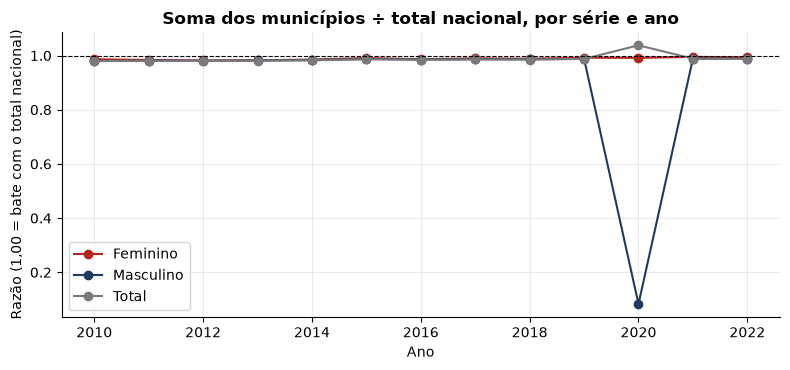

Leitura: a série feminina fica em 98%–100% do total nacional em todos os anos; já em 2020 a série masculina municipal soma só 8% do total nacional e a série total chega a 104% — erro evidente nessas duas séries, que será tratado na Seção 4.


In [7]:
nac = ref[ref.NIVNOME == "Brasil"].pivot_table(index="ano", columns="variavel", values="VALVALOR")
soma = p.groupby("ano")[VARS].sum(min_count=1)
razao = (soma / nac[VARS]).loc[2010:2022]
display(razao.T.round(3))
fora = (razao[["homicidios_feminino", "homicidios_masculino", "homicidios_total"]]
        .stack().loc[lambda s: (s < 0.95) | (s > 1.02)])
print("Combinações ano × série com soma municipal fora de [95%, 102%] do total nacional:")
print(fora.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(razao.index, razao.homicidios_feminino, marker="o", color=COR, label="Feminino")
ax.plot(razao.index, razao.homicidios_masculino, marker="o", color=COR2, label="Masculino")
ax.plot(razao.index, razao.homicidios_total, marker="o", color=COR3, label="Total")
ax.axhline(1, color="k", lw=0.8, ls="--")
ax.set_title("Soma dos municípios ÷ total nacional, por série e ano")
ax.set_xlabel("Ano"); ax.set_ylabel("Razão (1,00 = bate com o total nacional)"); ax.legend()
plt.tight_layout(); plt.show()
print("Leitura: a série feminina fica em %.0f%%–%.0f%% do total nacional em todos os anos; já em 2020 a série masculina municipal soma só %.0f%% do total nacional "
      "e a série total chega a %.0f%% — erro evidente nessas duas séries, que será tratado na Seção 4."
      % (razao.homicidios_feminino.min() * 100, razao.homicidios_feminino.max() * 100,
         razao.loc[2020, "homicidios_masculino"] * 100, razao.loc[2020, "homicidios_total"] * 100))

**Resumo do diagnóstico**

| Dimensão | Achado |
|---|---|
| Completude | Poucos municípios sem homicídios em **todos** os anos (criados depois de 2010 ou sem série); 26 linhas de população ausentes; 25 áreas ausentes |
| Validade | Sem negativos nem não inteiros; códigos válidos; população sempre positiva; **53 municípios com área = 0 km²** (ausente disfarçado) |
| Consistência | ~5% das linhas têm **sexo ignorado** (ausente disfarçado); há linhas com total < F+M; **2020 tem anomalia** |
| Unicidade | Sem duplicatas; todos os códigos existem na tabela de territórios |
| Acurácia | Série feminina bate com o nacional; **2020 masculino e total não batem** |

## 4. Tratamento dos dados  _(Responsável: Nicolas Toshio)_

Ordem aplicada: **(a) padronização → (b) ausentes e inválidos → (c) duplicatas → (d) imputação com critério → (e) sinalização de outliers**.
A base bruta continua intacta em `dados/`; a tratada é salva em arquivo separado.

In [8]:
antes = {
    "linhas": len(p),
    "homicidios_feminino ausentes": int(p.homicidios_feminino.isna().sum()),
    "homicidios_masculino ausentes": int(p.homicidios_masculino.isna().sum()),
    "homicidios_total ausentes": int(p.homicidios_total.isna().sum()),
    "populacao ausentes": int(p.populacao.isna().sum()),
    "duplicatas": int(dups),
}

# (a) Padronização: ano inteiro, código com 7 dígitos, nomes sem espaços sobrando, UF e região derivadas do código IBGE
t = p.copy()
t["ano"] = t.ano.astype(int)
t["TERCODIGO"] = t.TERCODIGO.astype(str).str.zfill(7)
info = terr[["TERCODIGO", "TERNOME", "TERCAPITAL", "TERAREA"]].copy()
info["TERNOME"] = info.TERNOME.str.strip()
info.loc[info.TERAREA <= 0, "TERAREA"] = np.nan          # área 0 km² é ausente disfarçado -> vira ausente de verdade (imputado no Pipeline)
print("(a) Áreas '0 km²' convertidas em ausentes:", int(terr.TERAREA.eq(0).sum()))
t = t.merge(info, on="TERCODIGO", how="left").rename(columns={"TERNOME": "nome", "TERAREA": "area_km2"})
t["uf"] = t.TERCODIGO.str[:2].map(UF_SIGLA)
t["regiao"] = t.TERCODIGO.str[0].map(REGIAO)
t["capital"] = (t.TERCAPITAL.fillna(False).astype(bool) | (t.TERCODIGO == "5300108")).astype(int)   # Brasília (DF) como capital
t = t.drop(columns="TERCAPITAL").sort_values(["TERCODIGO", "ano"]).reset_index(drop=True)
print("(a) UF/região derivadas; capitais:", int(t[t.ano == 2022].capital.sum()), "municípios.")

# (b) Ausentes e inválidos
# (b1) Anos cuja soma municipal destoa do total nacional (>2% acima ou <95%) são inválidos para aquela série:
inval = razao[["homicidios_masculino", "homicidios_total"]].stack().loc[lambda s: (s < 0.95) | (s > 1.02)]
print("(b1) Série × ano invalidados (viram ausentes e serão imputados):", [(c, a) for a, c in inval.index])
for a, c in inval.index:
    t.loc[t.ano == a, c] = np.nan
# (b2) Município-ano sem homicídio feminino NÃO vira zero (zero seria afirmar que ninguém morreu): a linha sai do painel
n_antes = len(t)
t = t.dropna(subset=["homicidios_feminino"]).copy()
print(f"(b2) Linhas removidas por falta de homicídio feminino: {n_antes - len(t)}")

# (c) Duplicatas
n_antes = len(t)
t = t.drop_duplicates(["TERCODIGO", "ano"])
print(f"(c) Duplicatas removidas: {n_antes - len(t)}")

# (d) Imputação com critério: interpolação linear DENTRO de cada município (usa o próprio histórico, não a média do país)
g = t.groupby("TERCODIGO")
t["imputado_pop"] = t.populacao.isna().astype(int)
t["imputado_serie"] = (t.homicidios_masculino.isna() | t.homicidios_total.isna()).astype(int)
for c in ["populacao", "homicidios_masculino", "homicidios_total"]:
    t[c] = g[c].transform(lambda s: s.interpolate(limit_direction="both"))
print("(d) Imputados por interpolação — população:", int(t.imputado_pop.sum()), "| série 2020 (masc./total):", int(t.imputado_serie.sum()))

# Variáveis derivadas
t["taxa_fem"] = t.homicidios_feminino / t.populacao * 100_000
t["taxa_total"] = t.homicidios_total / t.populacao * 100_000

# (e) Outliers: SINALIZADOS (não removidos), regra de 3×IQR acima do 3º quartil, só em municípios ≥ POP_MINIMA
ref_out = t[t.populacao >= POP_MINIMA].taxa_fem
q1, q3 = ref_out.quantile([0.25, 0.75]); corte = q3 + 3 * (q3 - q1)
t["outlier_taxa_fem"] = ((t.taxa_fem > corte) & (t.populacao >= POP_MINIMA)).astype(int)
print(f"(e) Outliers sinalizados: {t.outlier_taxa_fem.sum()} município-anos com taxa > {corte:.1f} por 100 mil (mantidos: podem ser reais)")

depois = {
    "linhas": len(t),
    "homicidios_feminino ausentes": int(t.homicidios_feminino.isna().sum()),
    "homicidios_masculino ausentes": int(t.homicidios_masculino.isna().sum()),
    "homicidios_total ausentes": int(t.homicidios_total.isna().sum()),
    "populacao ausentes": int(t.populacao.isna().sum()),
    "duplicatas": int(t.duplicated(["TERCODIGO", "ano"]).sum()),
}
display(pd.DataFrame({"antes": antes, "depois": depois}))

(a) Áreas '0 km²' convertidas em ausentes: 64
(a) UF/região derivadas; capitais: 27 municípios.
(b1) Série × ano invalidados (viram ausentes e serão imputados): [('homicidios_masculino', 2020), ('homicidios_total', 2020)]
(b2) Linhas removidas por falta de homicídio feminino: 111
(c) Duplicatas removidas: 0


(d) Imputados por interpolação — população: 26 | série 2020 (masc./total): 6096
(e) Outliers sinalizados: 112 município-anos com taxa > 14.4 por 100 mil (mantidos: podem ser reais)


,antes,depois
linhas,72410,72299
homicidios_feminino ausentes,111,0
homicidios_masculino ausentes,79,2
homicidios_total ausentes,608,0
populacao ausentes,26,0
duplicatas,0,0


**Decisões de tratamento (o quê · por quê · impacto)**

| Decisão | Por quê | Impacto |
|---|---|---|
| Invalidar masculino e total de 2020 e **interpolar** por município | A soma municipal não bate com o total nacional (diagnóstico 3.5); o erro vem da própria série | Os valores de 2020 dessas duas séries passam a ser estimativas; só a taxa total de 2020 é usada como atributo do modelo |
| **Não** preencher com zero os municípios sem homicídio feminino | Zero afirmaria “ninguém morreu”, quando na verdade não há dado | Linhas removidas; esses municípios não entram no modelo |
| Interpolar população ausente dentro do município | A população varia devagar; o histórico do próprio município é melhor que a média nacional | 26 linhas imputadas |
| Manter outliers sinalizados | Taxas altas em cidades de ~20 mil hab. podem ser reais (poucos casos pesam muito) | Coluna `outlier_taxa_fem`; nada removido |
| Converter **área = 0 km²** em ausente | Nenhum município tem área nula: é um ausente disfarçado, e dividir a população por zero geraria densidade infinita | 53 municípios ficam sem densidade; a imputação (mediana) é feita **dentro do Pipeline**, só com dados de treino |
| Deixar **sexo ignorado** como está | É uma limitação da fonte; não há como recuperar o sexo | Total ≠ F + M em ~5% das linhas; o modelo usa só a série feminina como principal sinal |

In [9]:
colunas = ["TERCODIGO", "ano", "nome", "uf", "regiao", "capital", "area_km2", "populacao", "homicidios_feminino",
           "homicidios_masculino", "homicidios_total", "taxa_fem", "taxa_total", "imputado_pop", "imputado_serie", "outlier_taxa_fem"]
t[colunas].to_csv(DADOS / "painel_municipio_ano_tratado.csv", index=False, encoding="utf-8")
tratado = t[colunas].copy()
print("Base tratada salva em dados/painel_municipio_ano_tratado.csv:", tratado.shape)

Base tratada salva em dados/painel_municipio_ano_tratado.csv: (72299, 16)


## 5. Análise exploratória  _(Responsável: Fernando Vinicius)_
Foco em municípios com **20 mil habitantes ou mais** (cobertura do modelo). Taxas em óbitos por 100 mil habitantes.

### 5.1 Tendência central, dispersão e forma

In [10]:
g22 = tratado[(tratado.ano == 2022) & (tratado.populacao >= POP_MINIMA)].copy()
x = g22.taxa_fem
desc = pd.DataFrame({
    "n (municípios)": [len(x)], "média": [x.mean()], "mediana": [x.median()], "moda (faixa de 1)": [x.round().mode().iloc[0]],
    "desvio-padrão": [x.std()], "coef. de variação": [x.std() / x.mean()], "mín": [x.min()], "Q1": [x.quantile(.25)],
    "Q3": [x.quantile(.75)], "máx": [x.max()], "assimetria": [x.skew()], "curtose": [x.kurt()],
})
display(desc.T.rename(columns={0: "taxa_fem, 2022"}))
print(f"Leitura: a média ({x.mean():.2f}) é maior que a mediana ({x.median():.2f}) e a assimetria é {x.skew():.2f} — distribuição "
      f"assimétrica à direita: poucos municípios têm taxas muito altas e {(x == 0).mean():.0%} não registraram nenhum homicídio de mulher em 2022.")

,"taxa_fem, 2022"
n (municípios),"1,775.00"
média,2.04
mediana,1.22
moda (faixa de 1),0.00
desvio-padrão,2.67
coef. de variação,1.31
mín,0.00
Q1,0.00
Q3,3.34
máx,24.64


Leitura: a média (2.04) é maior que a mediana (1.22) e a assimetria é 2.26 — distribuição assimétrica à direita: poucos municípios têm taxas muito altas e 43% não registraram nenhum homicídio de mulher em 2022.


### 5.2 Distribuição de frequências

Municípios ≥ 20 mil hab. por região (2022):


,absoluta,relativa (%),acumulada (%)
região,,,
Centro-Oeste,129,7.27,7.27
Nordeste,629,35.44,42.70
Norte,189,10.65,53.35
Sudeste,557,31.38,84.73
Sul,271,15.27,100.00


Faixas da taxa de homicídios de mulheres (por 100 mil), 2022:


,absoluta,relativa (%),acumulada (%)
faixa,,,
0,756,42.59,42.59
0–2,299,16.85,59.44
2–4,393,22.14,81.58
4–6,194,10.93,92.51
6–10,111,6.25,98.76
> 10,22,1.24,100.00


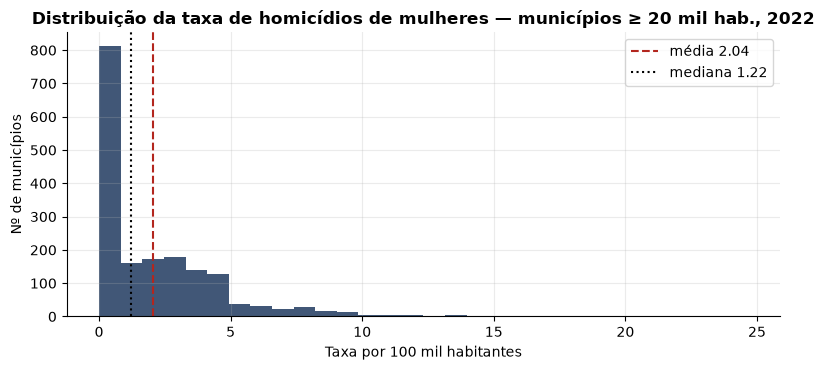

Leitura: a maior parte dos municípios está nas faixas baixas; só 7.5% passa de 6 por 100 mil.


In [11]:
def tabela_freq(serie, nome):
    f = serie.value_counts().sort_index() if serie.dtype != object else serie.value_counts()
    out = pd.DataFrame({"absoluta": f, "relativa (%)": f / f.sum() * 100})
    out["acumulada (%)"] = out["relativa (%)"].cumsum()
    out.index.name = nome
    return out

print("Municípios ≥ 20 mil hab. por região (2022):")
display(tabela_freq(g22.regiao, "região"))

faixas = pd.cut(g22.taxa_fem, [-0.01, 0, 2, 4, 6, 10, 100],
                labels=["0", "0–2", "2–4", "4–6", "6–10", "> 10"])
print("Faixas da taxa de homicídios de mulheres (por 100 mil), 2022:")
display(tabela_freq(faixas.astype(str).astype("object"), "faixa").reindex(["0", "0–2", "2–4", "4–6", "6–10", "> 10"]).assign(
    **{"acumulada (%)": lambda d: d["relativa (%)"].cumsum()}))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(x, bins=30, color=COR2, alpha=0.85)
ax.axvline(x.mean(), color=COR, ls="--", label=f"média {x.mean():.2f}")
ax.axvline(x.median(), color="k", ls=":", label=f"mediana {x.median():.2f}")
ax.set_title("Distribuição da taxa de homicídios de mulheres — municípios ≥ 20 mil hab., 2022")
ax.set_xlabel("Taxa por 100 mil habitantes"); ax.set_ylabel("Nº de municípios"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Leitura: a maior parte dos municípios está nas faixas baixas; só {(x > 6).mean():.1%} passa de 6 por 100 mil.")

### 5.3 Série no tempo

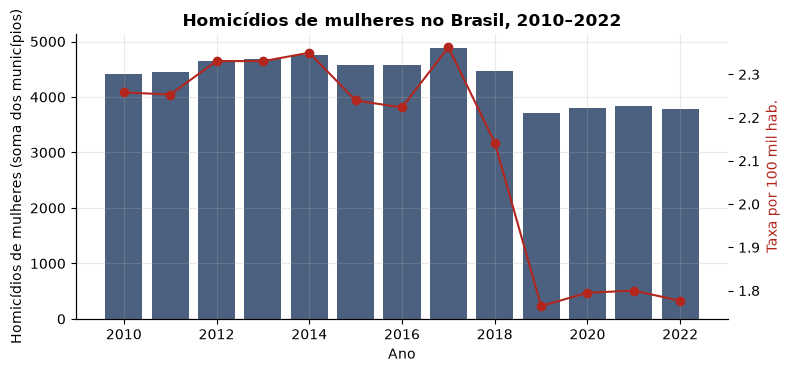

Leitura: o número de homicídios de mulheres foi de 4,415 (2010) a um pico de 4,885 em 2017, caiu para 3,707 em 2019 e ficou em 3,780 em 2022. Taxa: 2.26 → 1.78 por 100 mil.


In [12]:
serie = tratado.groupby("ano").agg(obitos=("homicidios_feminino", "sum"), pop=("populacao", "sum"))
serie["taxa"] = serie.obitos / serie["pop"] * 1e5
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(serie.index, serie.obitos, color=COR2, alpha=0.8)
ax.set_xlabel("Ano"); ax.set_ylabel("Homicídios de mulheres (soma dos municípios)")
ax2 = ax.twinx(); ax2.plot(serie.index, serie.taxa, color=COR, marker="o"); ax2.set_ylabel("Taxa por 100 mil hab.", color=COR); ax2.grid(False)
ax.set_title("Homicídios de mulheres no Brasil, 2010–2022")
plt.tight_layout(); plt.show()
pico = serie.obitos.idxmax()
print(f"Leitura: o número de homicídios de mulheres foi de {int(serie.obitos[2010]):,} (2010) a um pico de {int(serie.obitos[pico]):,} em {pico}, "
      f"caiu para {int(serie.obitos[2019]):,} em 2019 e ficou em {int(serie.obitos[2022]):,} em 2022. Taxa: {serie.taxa[2010]:.2f} → {serie.taxa[2022]:.2f} por 100 mil.")

### 5.4 Relações entre variáveis

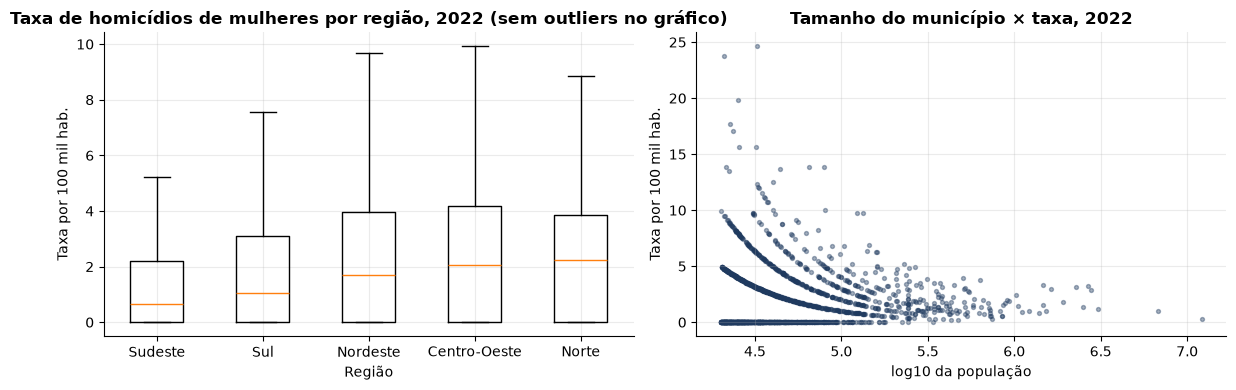

Leitura: a região com maior mediana é Norte (2.24) e a menor é Sudeste (0.66). A correlação de Spearman entre população e taxa é 0.14 (fraca) — associação, não causa.


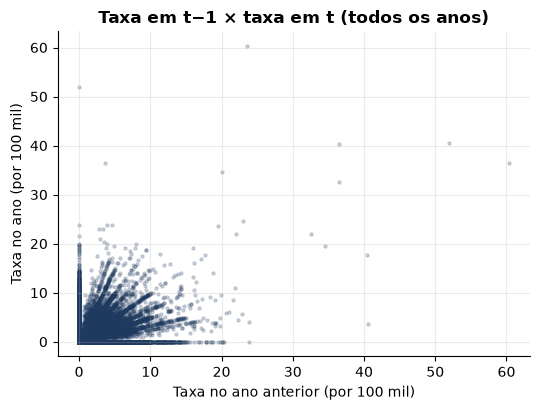

Leitura: correlação de Spearman entre a taxa de um ano e a do ano anterior = 0.19. Há persistência, mas com muito ruído — é o que o modelo tenta aproveitar.


In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))
ordem = g22.groupby("regiao").taxa_fem.median().sort_values().index
eixos[0].boxplot([g22[g22.regiao == r].taxa_fem for r in ordem], showfliers=False); eixos[0].set_xticks(range(1, len(ordem) + 1)); eixos[0].set_xticklabels(ordem)
eixos[0].set_title("Taxa de homicídios de mulheres por região, 2022 (sem outliers no gráfico)")
eixos[0].set_xlabel("Região"); eixos[0].set_ylabel("Taxa por 100 mil hab.")
eixos[1].scatter(np.log10(g22.populacao), g22.taxa_fem, s=8, alpha=0.4, color=COR2)
eixos[1].set_title("Tamanho do município × taxa, 2022")
eixos[1].set_xlabel("log10 da população"); eixos[1].set_ylabel("Taxa por 100 mil hab.")
plt.tight_layout(); plt.show()

rho = g22[["populacao", "taxa_fem"]].corr(method="spearman").iloc[0, 1]
med_reg = g22.groupby("regiao").taxa_fem.median().sort_values(ascending=False)
print(f"Leitura: a região com maior mediana é {med_reg.index[0]} ({med_reg.iloc[0]:.2f}) e a menor é {med_reg.index[-1]} ({med_reg.iloc[-1]:.2f}). "
      f"A correlação de Spearman entre população e taxa é {rho:.2f} (fraca) — associação, não causa.")

# persistência: a taxa de um ano ajuda a prever a do ano seguinte?
pares = tratado.merge(tratado[["TERCODIGO", "ano", "taxa_fem"]].assign(ano=lambda d: d.ano + 1), on=["TERCODIGO", "ano"], suffixes=("", "_ant"))
pares = pares[pares.populacao >= POP_MINIMA]
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.scatter(pares.taxa_fem_ant, pares.taxa_fem, s=5, alpha=0.2, color=COR2)
ax.set_title("Taxa em t−1 × taxa em t (todos os anos)"); ax.set_xlabel("Taxa no ano anterior (por 100 mil)"); ax.set_ylabel("Taxa no ano (por 100 mil)")
plt.tight_layout(); plt.show()
rho_p = pares[["taxa_fem_ant", "taxa_fem"]].corr(method="spearman").iloc[0, 1]
print(f"Leitura: correlação de Spearman entre a taxa de um ano e a do ano anterior = {rho_p:.2f}. Há persistência, mas com muito ruído — é o que o modelo tenta aproveitar.")

### 5.5 Três perguntas respondidas com números

In [14]:
# P1 — Quanto variou o total nacional?
v1 = (serie.obitos[2022] / serie.obitos[2010] - 1) * 100
v2 = (serie.obitos[2022] / serie.obitos[pico] - 1) * 100
print(f"P1. Como mudou o nº de homicídios de mulheres?  2010→2022: {v1:+.1f}%.  Do pico ({pico}) a 2022: {v2:+.1f}%.")

# P2 — Quais UFs têm as maiores taxas em 2022?
uf22 = tratado[tratado.ano == 2022].groupby("uf").agg(obitos=("homicidios_feminino", "sum"), pop=("populacao", "sum"))
uf22["taxa"] = uf22.obitos / uf22["pop"] * 1e5
top = uf22.taxa.sort_values(ascending=False)
print("P2. UFs com maior taxa em 2022:", ", ".join(f"{u} ({v:.1f})" for u, v in top.head(5).items()),
      "| menores:", ", ".join(f"{u} ({v:.1f})" for u, v in top.tail(3).items()), "por 100 mil hab.")

# P3 — Municípios maiores têm taxas maiores?
g22["porte"] = pd.cut(g22.populacao, [0, 50_000, 100_000, 500_000, 1e9], labels=["20–50 mil", "50–100 mil", "100–500 mil", "> 500 mil"])
por_porte = g22.groupby("porte", observed=True).taxa_fem.agg(["count", "median", "mean"])
print("P3. Taxa por porte do município (2022):")
display(por_porte)
print(f"    Spearman população × taxa = {rho:.2f}. Os grandes municípios não têm taxa muito diferente; a associação é fraca e não indica causa.")

P1. Como mudou o nº de homicídios de mulheres?  2010→2022: -14.4%.  Do pico (2017) a 2022: -22.6%.
P2. UFs com maior taxa em 2022: RR (4.6), RO (3.6), CE (3.0), MT (3.0), BA (2.7) | menores: SC (1.2), DF (1.1), SP (0.8) por 100 mil hab.
P3. Taxa por porte do município (2022):


,count,median,mean
porte,,,
20–50 mil,1099,0.00,2.11
50–100 mil,344,1.67,2.06
100–500 mil,283,1.50,1.84
> 500 mil,49,1.40,1.64


    Spearman população × taxa = 0.14. Os grandes municípios não têm taxa muito diferente; a associação é fraca e não indica causa.


## 6. Modelagem  _(Responsável: Fernando Vinicius)_

**Objetivo.** Classificar se um município estará, no ano *t*, no grupo de **“alta taxa”** de homicídios de mulheres, usando só o que se sabe até o ano *t − 1*.

**Variável-alvo (`alto`).** `1` se `taxa_fem` do ano *t* ≥ **limiar**, onde o limiar é o **3º quartil** das taxas dos municípios ≥ 20 mil hab. nos **anos de treino**
(depois, o mesmo limiar fixo é aplicado ao teste e às estimativas futuras — sem olhar para o futuro).

**Cobertura.** Apenas municípios com ≥ 20 mil habitantes em *t − 1*: abaixo disso as taxas oscilam demais com 1–2 casos e há risco maior de reidentificação.

**Atributos (todos de *t − 1* ou anteriores):** taxa feminina em *t−1*, *t−2*, *t−3*; média dos 3 anos; tendência (*t−1* menos *t−2*);
taxa total de homicídios em *t−1*; log10 da população; log10 da densidade; indicador de capital; região.

**Divisão e validação.**
- **Teste temporal:** anos-alvo **2021 e 2022** ficam de fora de tudo (como o futuro de verdade).
- **Treino:** anos-alvo 2013–2020, com **validação cruzada em 5 partes** (`StratifiedGroupKFold` — agrupa por município para o mesmo município não aparecer em treino e validação, e preserva a proporção de classes).
- Imputação e escalonamento ficam **dentro do Pipeline**, ajustados só no treino de cada partição.
- **Limiar de decisão:** como só ~25% dos municípios são “alto”, o corte padrão de 0,5 quase nunca dispara (numa primeira versão deste notebook o recall no teste foi de apenas 6%).
  O corte de cada modelo é escolhido na validação cruzada, nas probabilidades *fora da amostra*, maximizando o F1; o teste não participa dessa escolha.

**Modelos:** (0) linha de base “persistência” (repete a classe do ano anterior), (1) **Regressão Logística**, (2) **Random Forest**.
**Métricas:** acurácia, precisão, recall, F1, ROC-AUC e matriz de confusão (a classe “alto” é a minoritária; acurácia sozinha engana).

In [15]:
def lag(df, col, k):
    x = df[["TERCODIGO", "ano", col]].copy()
    x["ano"] = x.ano + k
    return x.rename(columns={col: f"{col}_t{k}"})

base = tratado[["TERCODIGO", "ano", "nome", "uf", "regiao", "capital", "area_km2", "taxa_fem"]].rename(columns={"taxa_fem": "taxa_fem_alvo"})
anos_alvo = list(range(2013, 2024))                       # 2023 = ano a estimar (sem alvo ainda)
quadro = pd.DataFrame([(c, a) for c in tratado.TERCODIGO.unique() for a in anos_alvo], columns=["TERCODIGO", "ano"])
quadro = quadro.merge(base.drop(columns=["capital", "area_km2", "nome", "uf", "regiao"]), on=["TERCODIGO", "ano"], how="left")
for k in (1, 2, 3):
    quadro = quadro.merge(lag(tratado, "taxa_fem", k), on=["TERCODIGO", "ano"], how="left")
quadro = quadro.merge(lag(tratado, "taxa_total", 1), on=["TERCODIGO", "ano"], how="left")
quadro = quadro.merge(lag(tratado, "populacao", 1), on=["TERCODIGO", "ano"], how="left")
estat = tratado.drop_duplicates("TERCODIGO")[["TERCODIGO", "nome", "uf", "regiao", "capital", "area_km2"]]
quadro = quadro.merge(estat, on="TERCODIGO", how="left")

quadro["media3"] = quadro[["taxa_fem_t1", "taxa_fem_t2", "taxa_fem_t3"]].mean(axis=1)
quadro["tendencia"] = quadro.taxa_fem_t1 - quadro.taxa_fem_t2
quadro["log_pop"] = np.log10(quadro.populacao_t1)
quadro["log_dens"] = np.log10(quadro.populacao_t1 / quadro.area_km2)

NUM = ["taxa_fem_t1", "taxa_fem_t2", "taxa_fem_t3", "media3", "tendencia", "taxa_total_t1", "log_pop", "log_dens", "capital"]
CAT = ["regiao"]

elegiveis = quadro[(quadro.populacao_t1 >= POP_MINIMA) & quadro[["taxa_fem_t1", "taxa_fem_t2", "taxa_fem_t3"]].notna().all(axis=1)].copy()
treino_mask = elegiveis.ano.isin(ANOS_TREINO)
LIMIAR = elegiveis[treino_mask].taxa_fem_alvo.quantile(0.75)          # 3º quartil dos anos de treino
elegiveis["alto"] = (elegiveis.taxa_fem_alvo >= LIMIAR).astype(float)
elegiveis.loc[elegiveis.taxa_fem_alvo.isna(), "alto"] = np.nan
print(f"Limiar de 'alta taxa' (3º quartil nos anos de treino): {LIMIAR:.2f} homicídios de mulheres por 100 mil hab.")

tr = elegiveis[elegiveis.ano.isin(ANOS_TREINO)]
te = elegiveis[elegiveis.ano.isin(ANOS_TESTE)]
futuro = elegiveis[elegiveis.ano == 2023].copy()
X_tr, y_tr, g_tr = tr[NUM + CAT], tr.alto.astype(int), tr.TERCODIGO
X_te, y_te = te[NUM + CAT], te.alto.astype(int)
print(f"Treino: {len(tr):,} município-anos · Teste: {len(te):,} · A estimar (2023): {len(futuro):,} municípios")
print(f"Proporção da classe 'alto' — treino: {y_tr.mean():.1%} · teste: {y_te.mean():.1%}")
print(f"Atributos com ausentes no treino (serão imputados no Pipeline): {X_tr[NUM].isna().sum()[lambda s: s > 0].to_dict()}")

Limiar de 'alta taxa' (3º quartil nos anos de treino): 3.65 homicídios de mulheres por 100 mil hab.
Treino: 13,954 município-anos · Teste: 3,589 · A estimar (2023): 1,775 municípios
Proporção da classe 'alto' — treino: 25.0% · teste: 22.3%
Atributos com ausentes no treino (serão imputados no Pipeline): {'log_dens': 24}


In [16]:
def prep(escalar):
    num = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    return ColumnTransformer([("num", Pipeline(num), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

modelos = {
    "Regressão Logística": Pipeline([("pre", prep(True)), ("m", LogisticRegression(max_iter=2000, C=1.0))]),
    "Random Forest": Pipeline([("pre", prep(False)),
                               ("m", RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=25,
                                                            n_jobs=-1, random_state=ALEATORIO))]),
}
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=ALEATORIO)
particoes = list(cv.split(X_tr, y_tr, g_tr))        # as MESMAS 5 partições para todos os modelos

def met(y, pred, escore):
    return {"acuracia": accuracy_score(y, pred), "precisao": precision_score(y, pred, zero_division=0),
            "recall": recall_score(y, pred), "f1": f1_score(y, pred), "auc": roc_auc_score(y, escore)}

cv_resultados, LIMIARES = {}, {}
# Linha de base: repete a classe do ano anterior (taxa em t-1 >= limiar de alta taxa)
cv_resultados["Linha de base (persistência)"] = pd.DataFrame([
    met(y_tr.iloc[i_va], (X_tr.iloc[i_va].taxa_fem_t1 >= LIMIAR).astype(int), X_tr.iloc[i_va].taxa_fem_t1) for _, i_va in particoes])

for nome, pipe in modelos.items():
    # 1) probabilidades "fora da amostra": cada município é previsto por um modelo que NÃO o viu no treino
    oof = np.zeros(len(y_tr))
    for i_tr, i_va in particoes:
        pipe.fit(X_tr.iloc[i_tr], y_tr.iloc[i_tr])
        oof[i_va] = pipe.predict_proba(X_tr.iloc[i_va])[:, 1]
    # 2) limiar de decisão: como só ~25% são 'alto', o corte padrão (0,5) quase nunca dispara e o recall despenca.
    #    Escolhemos o corte que maximiza o F1 nessas probabilidades fora da amostra (o teste NÃO participa).
    candidatos = np.round(np.arange(0.05, 0.71, 0.01), 2)
    LIMIARES[nome] = float(candidatos[int(np.argmax([f1_score(y_tr, oof >= c) for c in candidatos]))])
    cv_resultados[nome] = pd.DataFrame([met(y_tr.iloc[i_va], (oof[i_va] >= LIMIARES[nome]).astype(int), oof[i_va]) for _, i_va in particoes])
print("Limiar de decisão escolhido na validação cruzada:", {k: v for k, v in LIMIARES.items()})

resumo_cv = pd.DataFrame({n: d.mean() for n, d in cv_resultados.items()}).T
resumo_cv_dp = pd.DataFrame({n: d.std() for n, d in cv_resultados.items()}).T
print("Validação cruzada (5 partes) — média de cada métrica:")
display(resumo_cv)
print("Desvio-padrão entre as partes:")
display(resumo_cv_dp)
print("F1 por parte:")
display(pd.DataFrame({n: d.f1.round(3) for n, d in cv_resultados.items()}).T.rename(columns=lambda c: f"parte {c + 1}"))

MODELO_ESCOLHIDO = resumo_cv.loc[list(modelos)].auc.idxmax()
print(f"\nModelo escolhido (maior ROC-AUC médio na validação cruzada): {MODELO_ESCOLHIDO}")

Limiar de decisão escolhido na validação cruzada: {'Regressão Logística': 0.22, 'Random Forest': 0.25}
Validação cruzada (5 partes) — média de cada métrica:


,acuracia,precisao,recall,f1,auc
Linha de base (persistência),0.69,0.38,0.39,0.39,0.58
Regressão Logística,0.63,0.37,0.70,0.49,0.71
Random Forest,0.64,0.39,0.74,0.51,0.73


Desvio-padrão entre as partes:


,acuracia,precisao,recall,f1,auc
Linha de base (persistência),0.01,0.01,0.01,0.01,0.01
Regressão Logística,0.01,0.01,0.02,0.01,0.01
Random Forest,0.01,0.01,0.02,0.01,0.01


F1 por parte:


,parte 1,parte 2,parte 3,parte 4,parte 5
Linha de base (persistência),0.41,0.39,0.37,0.38,0.38
Regressão Logística,0.48,0.50,0.48,0.49,0.48
Random Forest,0.50,0.52,0.50,0.51,0.51



Modelo escolhido (maior ROC-AUC médio na validação cruzada): Random Forest


## 7. Avaliação no teste (anos 2021 e 2022)  _(Responsável: Fernando Vinicius)_
O teste nunca foi usado para escolher modelo, limiar ou atributos.

,acuracia,precisao,recall,f1,auc
Linha de base (persistência),0.72,0.37,0.36,0.37,0.57
Regressão Logística,0.65,0.35,0.68,0.46,0.72
Random Forest,0.67,0.38,0.70,0.49,0.74


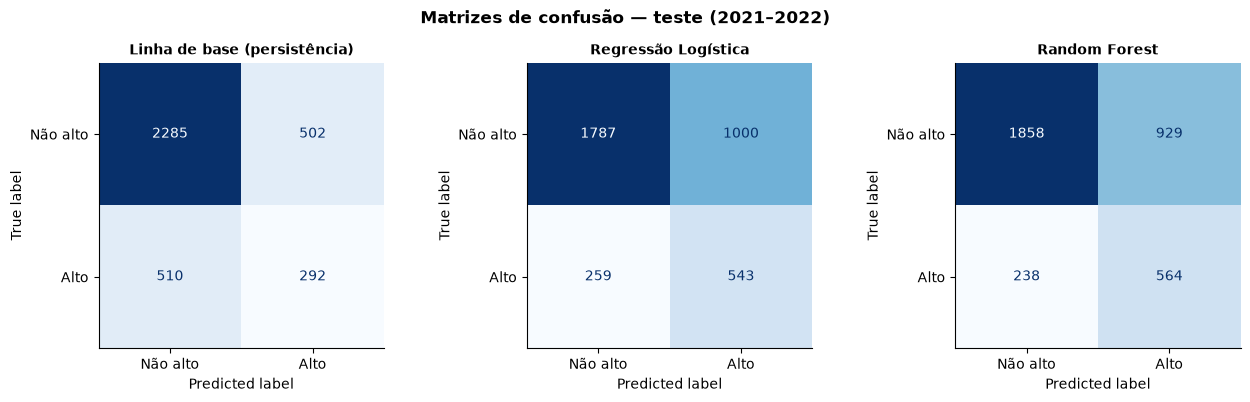

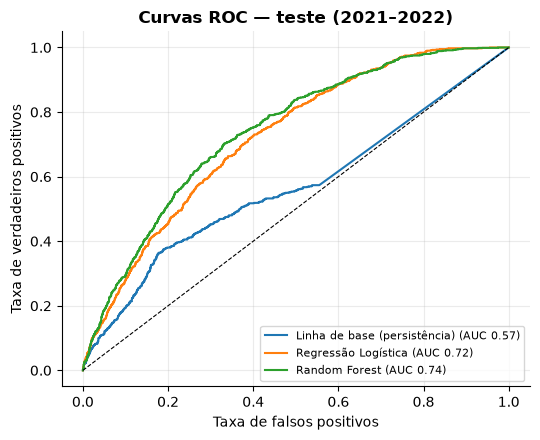

Leitura honesta: o modelo escolhido (Random Forest, limiar 0.25) tem ROC-AUC 0.74, F1 0.49, recall 0.70 e precisão 0.38 no teste; a linha de base tem AUC 0.57 e F1 0.37 — o modelo supera a linha de base. Só ~22% dos municípios são 'alto', então a acurácia (0.67) engana. A precisão de 38% significa que a maioria dos municípios sinalizados como 'alto' NÃO termina no grupo de alta taxa: é um indicador grosseiro de contexto, jamais um diagnóstico.


In [17]:
def metricas(y, pred, proba):
    return {"acuracia": accuracy_score(y, pred), "precisao": precision_score(y, pred), "recall": recall_score(y, pred),
            "f1": f1_score(y, pred), "auc": roc_auc_score(y, proba)}

teste_res, preds = {}, {}
pred_base = (X_te.taxa_fem_t1 >= LIMIAR).astype(int)
teste_res["Linha de base (persistência)"] = metricas(y_te, pred_base, X_te.taxa_fem_t1)
preds["Linha de base (persistência)"] = (pred_base, X_te.taxa_fem_t1)
ajustados = {}
for nome, pipe in modelos.items():
    pipe.fit(X_tr, y_tr)
    ajustados[nome] = pipe
    proba = pipe.predict_proba(X_te)[:, 1]
    pred = (proba >= LIMIARES[nome]).astype(int)          # limiar definido só com dados de treino
    teste_res[nome] = metricas(y_te, pred, proba)
    preds[nome] = (pred, proba)
tab_teste = pd.DataFrame(teste_res).T
display(tab_teste)

fig, eixos = plt.subplots(1, 3, figsize=(13, 4))
for ax, (nome, (pred, _)) in zip(eixos, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Não alto", "Alto"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nome, fontsize=10); ax.grid(False)
fig.suptitle("Matrizes de confusão — teste (2021–2022)", fontweight="bold")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for nome, (_, proba) in preds.items():
    fpr, tpr, _ = roc_curve(y_te, proba)
    ax.plot(fpr, tpr, label=f"{nome} (AUC {roc_auc_score(y_te, proba):.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=0.8)
ax.set_title("Curvas ROC — teste (2021–2022)"); ax.set_xlabel("Taxa de falsos positivos"); ax.set_ylabel("Taxa de verdadeiros positivos"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

melhor = tab_teste.loc[MODELO_ESCOLHIDO]; base_ = tab_teste.loc["Linha de base (persistência)"]
vs = "supera" if (melhor.auc > base_.auc and melhor.f1 > base_.f1) else "NÃO supera em todas as métricas"
print(f"Leitura honesta: o modelo escolhido ({MODELO_ESCOLHIDO}, limiar {LIMIARES[MODELO_ESCOLHIDO]:.2f}) tem ROC-AUC {melhor.auc:.2f}, F1 {melhor.f1:.2f}, recall {melhor.recall:.2f} e precisão {melhor.precisao:.2f} no teste; "
      f"a linha de base tem AUC {base_.auc:.2f} e F1 {base_.f1:.2f} — o modelo {vs} a linha de base. "
      f"Só ~{y_te.mean():.0%} dos municípios são 'alto', então a acurácia ({melhor.acuracia:.2f}) engana. "
      f"A precisão de {melhor.precisao:.0%} significa que a maioria dos municípios sinalizados como 'alto' NÃO termina no grupo de alta taxa: "
      "é um indicador grosseiro de contexto, jamais um diagnóstico.")

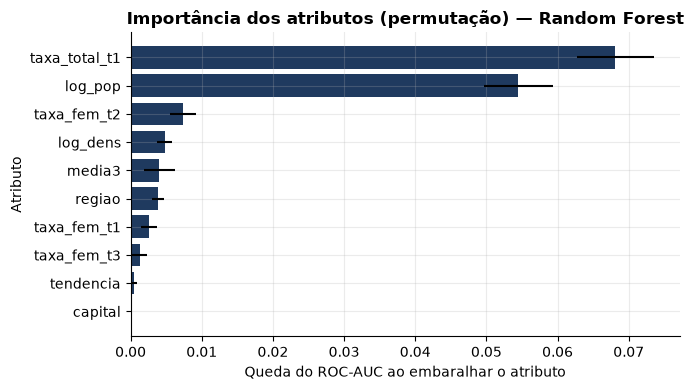

Leitura: os atributos que mais derrubam o AUC quando embaralhados são taxa_total_t1, log_pop, taxa_fem_t2 (em ordem decrescente de importância). Importância mede o quanto o modelo usa o atributo, não é causa.


In [18]:
imp = permutation_importance(ajustados[MODELO_ESCOLHIDO], X_te, y_te, scoring="roc_auc", n_repeats=10, random_state=ALEATORIO)
imp_df = pd.Series(imp.importances_mean, index=NUM + CAT).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(imp_df.index, imp_df.values, xerr=pd.Series(imp.importances_std, index=NUM + CAT)[imp_df.index], color=COR2)
ax.set_title(f"Importância dos atributos (permutação) — {MODELO_ESCOLHIDO}")
ax.set_xlabel("Queda do ROC-AUC ao embaralhar o atributo"); ax.set_ylabel("Atributo")
plt.tight_layout(); plt.show()
print("Leitura: os atributos que mais derrubam o AUC quando embaralhados são", ", ".join(imp_df.index[::-1][:3]),
      "(em ordem decrescente de importância). Importância mede o quanto o modelo usa o atributo, não é causa.")

## 8. Integração com a API e o app  _(Responsável: Nicolas Toshio)_

O modelo escolhido é **reajustado com todos os anos disponíveis (2013–2022)** e estima, para cada município com ≥ 20 mil hab., a probabilidade de estar no grupo
de alta taxa em **2023**, usando os dados de 2022 e anteriores. O resultado é gravado em `../api/dados/risco_territorial.json`; a API o serve em `GET /risco-territorial` e o app mostra a **categoria**
no Espaço Seguro, sempre com o aviso de estimativa acadêmica.

| Categoria do município | Regra (probabilidade estimada de estar no grupo de alta taxa) |
|---|---|
| Baixo | probabilidade < **BAIXO_ATE** |
| Médio | **BAIXO_ATE** ≤ probabilidade < **ALTO_DE** |
| Alto | probabilidade ≥ **ALTO_DE** |

Os cortes são escolhidos olhando a **calibração no teste** (tabela abaixo): em cada faixa, qual a fração de municípios que de fato ficou no grupo de alta taxa?
Para comparação, a taxa-base é ~25%.

A categoria da **UF** é relativa: a UF é Baixo/Médio/Alto conforme o tercil da probabilidade média dos seus municípios (comparada às demais UFs).

In [19]:
final = Pipeline(modelos[MODELO_ESCOLHIDO].steps)            # mesma configuração, reajustada com treino + teste
tudo = elegiveis[elegiveis.ano.isin(list(ANOS_TREINO) + ANOS_TESTE)]
final.fit(tudo[NUM + CAT], tudo.alto.astype(int))
futuro["probabilidade"] = final.predict_proba(futuro[NUM + CAT])[:, 1]

BAIXO_ATE, ALTO_DE = 0.20, 0.40
def categoria(p):
    return "Baixo" if p < BAIXO_ATE else ("Médio" if p < ALTO_DE else "Alto")

# Calibração no teste (modelo ajustado só com treino): em cada faixa, quantos municípios REALMENTE ficaram em 'alta taxa'?
p_te = ajustados[MODELO_ESCOLHIDO].predict_proba(X_te)[:, 1]
calib = pd.DataFrame({"categoria": pd.Series(p_te).map(categoria).values, "alto_real": y_te.values})
calib = calib.groupby("categoria").alto_real.agg(municipios_ano="size", fracao_que_foi_alta="mean").reindex(["Baixo", "Médio", "Alto"])
print("Calibração no teste (2021–2022): fração de municípios que de fato ficou no grupo de alta taxa, por categoria prevista")
display(calib)
futuro["categoria"] = futuro.probabilidade.map(categoria)
print("Municípios estimados para 2023:", len(futuro))
display(futuro.categoria.value_counts().rename("municípios").to_frame().assign(**{"%": lambda d: d["municípios"] / d["municípios"].sum() * 100}))

nomes_uf = dict(zip(terr_uf.TERCODIGO, terr_uf.TERNOME))
ufs = futuro.groupby("uf").agg(regiao=("regiao", "first"), municipios_modelados=("TERCODIGO", "size"),
                               municipios_alto=("categoria", lambda s: int((s == "Alto").sum())),
                               probabilidade_media=("probabilidade", "mean")).reset_index()
t1, t2 = ufs.probabilidade_media.quantile([1 / 3, 2 / 3])
ufs["categoria"] = ufs.probabilidade_media.map(lambda v: "Baixo" if v < t1 else ("Médio" if v < t2 else "Alto"))
inv = {v: k for k, v in UF_SIGLA.items()}
ufs["nome"] = ufs.uf.map(lambda s: nomes_uf.get(inv[s], s))
display(ufs.sort_values("probabilidade_media", ascending=False).head(8))

AVISO = ("Estimativa acadêmica baseada em dados públicos agregados (Atlas da Violência/Ipea). Indica o contexto do município, "
         "não o risco de uma pessoa, e não substitui os serviços oficiais. Em risco imediato, ligue 190 ou 180.")
saida = {
    "metadados": {
        "titulo": "Indicador de contexto territorial — homicídios de mulheres",
        "aviso": AVISO,
        "fonte": "Atlas da Violência (Ipea), séries municipais AVIOL12 via Ipeadata; SIM/DataSUS; população TCU/IBGE",
        "ano_dados_referencia": 2022, "ano_estimado": 2023,
        "definicao_alto": f"Município entre os 25% com maior taxa de homicídios de mulheres (>= {LIMIAR:.2f} por 100 mil hab., municípios com 20 mil hab. ou mais)",
        "populacao_minima": POP_MINIMA,
        "faixas_municipio": {"Baixo": f"< {BAIXO_ATE:.0%}", "Médio": f"{BAIXO_ATE:.0%} a {ALTO_DE:.0%}", "Alto": f">= {ALTO_DE:.0%}"},
        "calibracao_teste": {k: round(float(v), 3) for k, v in calib.fracao_que_foi_alta.items()},
        "limiar_decisao_modelo": LIMIARES[MODELO_ESCOLHIDO],
        "faixas_uf": "tercis da probabilidade média dos municípios, comparando as UFs",
        "modelo": MODELO_ESCOLHIDO,
        "metricas_teste_2021_2022": {k: round(float(v), 3) for k, v in tab_teste.loc[MODELO_ESCOLHIDO].items()},
        "metricas_validacao_cruzada_5_partes": {k: round(float(v), 3) for k, v in resumo_cv.loc[MODELO_ESCOLHIDO].items()},
        "gerado_em": datetime.date.today().isoformat(),
    },
    "ufs": [{"uf": r.uf, "nome": r.nome, "regiao": r.regiao, "categoria": r.categoria,
             "probabilidade_media": round(float(r.probabilidade_media), 3),
             "municipios_modelados": int(r.municipios_modelados), "municipios_alto": int(r.municipios_alto)}
            for r in ufs.sort_values("uf").itertuples()],
    "municipios": [{"codigo": r.TERCODIGO, "nome": r.nome, "uf": r.uf, "probabilidade": round(float(r.probabilidade), 3), "categoria": r.categoria}
                   for r in futuro.sort_values(["uf", "nome"]).itertuples()],
}
destino = pathlib.Path("..") / "api" / "dados" / "risco_territorial.json"
destino.write_text(json.dumps(saida, ensure_ascii=False, indent=1), encoding="utf-8")
print(f"Gravado: {destino} ({destino.stat().st_size / 1024:.0f} KB) — {len(saida['municipios'])} municípios, {len(saida['ufs'])} UFs")

# Conferência da integração: relê o arquivo e mostra exemplos
conf = json.loads(destino.read_text(encoding="utf-8"))
print("\nExemplos (o que o app mostra):")
for cod in ["3550308", "3304557", "5300108", "2927408"]:
    m = next((x for x in conf["municipios"] if x["codigo"] == cod), None)
    if m:
        print(f"  {m['nome']}/{m['uf']}: {m['categoria']} (probabilidade {m['probabilidade']:.0%})")
print("\nAviso exibido junto:", conf["metadados"]["aviso"])

Calibração no teste (2021–2022): fração de municípios que de fato ficou no grupo de alta taxa, por categoria prevista


,municipios_ano,fracao_que_foi_alta
categoria,,
Baixo,1747,0.09
Médio,1478,0.29
Alto,364,0.57


Municípios estimados para 2023: 1775


,municípios,%
categoria,,
Baixo,883,49.75
Médio,713,40.17
Alto,179,10.08


,uf,regiao,municipios_modelados,municipios_alto,probabilidade_media,categoria,nome
12,MT,Centro-Oeste,37,12,0.33,Alto,Mato Grosso
21,RR,Norte,4,1,0.33,Alto,Roraima
4,BA,Nordeste,170,49,0.32,Alto,Bahia
11,MS,Centro-Oeste,34,5,0.29,Alto,Mato Grosso do Sul
1,AL,Nordeste,40,4,0.29,Alto,Alagoas
5,CE,Nordeste,101,20,0.29,Alto,Ceará
20,RO,Norte,19,3,0.29,Alto,Rondônia
3,AP,Norte,6,0,0.29,Alto,Amapá


Gravado: ..\api\dados\risco_territorial.json (236 KB) — 1775 municípios, 27 UFs

Exemplos (o que o app mostra):
  São Paulo/SP: Baixo (probabilidade 4%)
  Rio de Janeiro/RJ: Baixo (probabilidade 4%)
  Brasília/DF: Baixo (probabilidade 7%)
  Salvador/BA: Médio (probabilidade 26%)

Aviso exibido junto: Estimativa acadêmica baseada em dados públicos agregados (Atlas da Violência/Ipea). Indica o contexto do município, não o risco de uma pessoa, e não substitui os serviços oficiais. Em risco imediato, ligue 190 ou 180.


## 9. Limitações, ética e conclusão

- **Indicador do território, não da pessoa.** Dois municípios com a mesma categoria podem ter realidades muito diferentes; uma mulher em município “Baixo” pode estar em perigo grave. O app exibe o aviso em todas as telas do indicador.
- **Só violência letal.** A subnotificação da violência não letal é grande; o indicador não a captura.
- **Qualidade da fonte.** Houve erro na série municipal de 2020 (masculino e total), tratado por interpolação e documentado; o sexo ignorado (~5% das linhas) não foi recuperado.
- **Pequenos números.** Por isso a cobertura é de municípios com 20 mil hab. ou mais; abaixo disso o app só mostra a UF.
- **Desempenho moderado.** Veja as tabelas das Seções 6 e 7: o ROC-AUC fica na faixa de 0,7 e a precisão da classe “alto” é baixa — muitos municípios sinalizados não ficam de fato no grupo de alta taxa. Parte disso é ruído inevitável (com poucos casos por município, um único óbito muda a classe). Melhorias possíveis: atributos socioeconômicos (renda, escolaridade), dados do Ligue 180 e de boletins de ocorrência, e calibração das probabilidades.
- **Correlação não é causa.** Nenhuma relação aqui permite concluir causalidade.

**Conclusão.** O pipeline está completo e reproduzível: base pública real → governança e qualidade (com um erro real encontrado e tratado) → tratamento documentado → EDA → dois modelos e uma linha de base com validação cruzada → avaliação em teste temporal → resultado integrado à API e ao app, sempre com o aviso de estimativa acadêmica.